In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PowerTransformer

In [2]:
df_train = pd.read_csv("train.csv")
df_val = pd.read_csv("val.csv")
df_test = pd.read_csv("test.csv")

In [3]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1000000 non-null  object 
 1   vendor_id           1000000 non-null  int64  
 2   pickup_datetime     1000000 non-null  object 
 3   passenger_count     1000000 non-null  int64  
 4   pickup_longitude    1000000 non-null  float64
 5   pickup_latitude     1000000 non-null  float64
 6   dropoff_longitude   1000000 non-null  float64
 7   dropoff_latitude    1000000 non-null  float64
 8   store_and_fwd_flag  1000000 non-null  object 
 9   trip_duration       1000000 non-null  int64  
dtypes: float64(4), int64(3), object(3)
memory usage: 76.3+ MB


In [4]:
df_train.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [5]:
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
vendor_id,1000000.0,1.534793,0.498788,1.000000,1.000000,2.000000,2.000000,2.000000e+00
passenger_count,1000000.0,1.665353,1.315723,0.000000,1.000000,1.000000,2.000000,7.000000e+00
pickup_longitude,1000000.0,-73.973475,0.065404,-121.933342,-73.991852,-73.981728,-73.967346,-6.133553e+01
pickup_latitude,1000000.0,40.750947,0.033745,34.359695,40.737372,40.754131,40.768379,5.188108e+01
dropoff_longitude,1000000.0,-73.973421,0.065432,-121.933304,-73.991341,-73.979767,-73.963036,-6.133553e+01
dropoff_latitude,1000000.0,40.751829,0.035782,34.359695,40.735928,40.754551,40.769833,4.392103e+01
trip_duration,1000000.0,954.884971,3882.070116,1.000000,397.000000,662.000000,1074.000000,2.227612e+06


In [6]:
def calculate_distance(lat1, lon1, lat2, lon2):
    R = 6371  

    lat1, lon1, lat2, lon2 = map(np.radians, 
                                 [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat/2)**2 + \
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2

    c = 2 * np.arcsin(np.sqrt(a))
    return R * c
df_train['distance_km'] = calculate_distance(df_train['pickup_latitude'],df_train['pickup_longitude'],df_train['dropoff_latitude'],df_train['dropoff_longitude'])
df_val['distance_km'] = calculate_distance(df_val['pickup_latitude'],df_val['pickup_longitude'],df_val['dropoff_latitude'],df_val['dropoff_longitude'])
df_test['distance_km'] = calculate_distance(df_test['pickup_latitude'],df_test['pickup_longitude'],df_test['dropoff_latitude'],df_test['dropoff_longitude'])

In [7]:
df_train['duration_minutes'] = df_train['trip_duration'] / 60
df_val['duration_minutes'] = df_val['trip_duration'] / 60

df_train['real_speed_kmh'] = df_train['distance_km'] / (df_train['duration_minutes'] / 60)
df_val['real_speed_kmh'] = df_val['distance_km'] / (df_val['duration_minutes'] / 60)


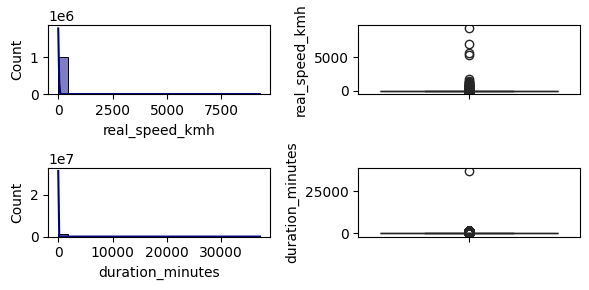

In [8]:
plt.figure(figsize=(6,3))

plt.subplot(2,2,1)
sns.histplot(df_train['real_speed_kmh'], bins=20, kde=True, color='navy')

plt.subplot(2,2,2)
sns.boxplot(data=df_train, y='real_speed_kmh', color='navy')

plt.subplot(2,2,3)
sns.histplot(df_train['duration_minutes'], bins=20, kde=True, color='navy')

plt.subplot(2,2,4)
sns.boxplot(data=df_train, y='duration_minutes', color='navy')

plt.tight_layout()
plt.show()

In [9]:
def handle_out_of_nyc(df):
    nyc_longitude = (-74.03, -73.77)
    nyc_latitude  = (40.63, 40.85)
    df = df[
        df['pickup_longitude'].between(*nyc_longitude) &
        df['pickup_latitude'].between(*nyc_latitude) &
        df['dropoff_longitude'].between(*nyc_longitude) &
        df['dropoff_latitude'].between(*nyc_latitude)
    ]
    return df
df_train = handle_out_of_nyc(df_train)
df_val = handle_out_of_nyc(df_val)
df_test = handle_out_of_nyc(df_test)

<Axes: xlabel='distance_km', ylabel='Count'>

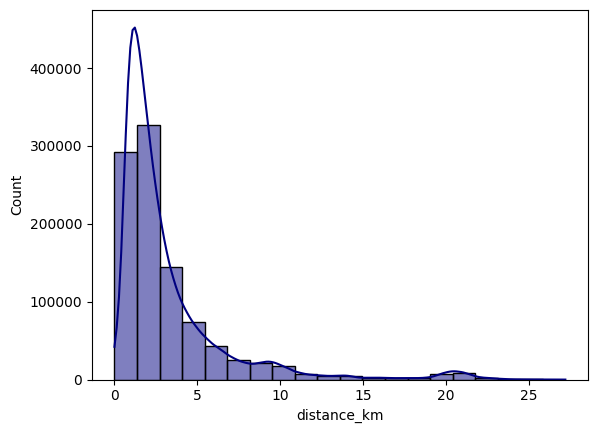

In [10]:
sns.histplot(df_train['distance_km'],bins = 20, kde = True, color='navy')

In [11]:
df_train = df_train[df_train['distance_km'] > 0]
df_val = df_val[df_val['distance_km'] > 0]

In [12]:
mask_clean_train = (df_train['real_speed_kmh'] < 160) & (df_train['real_speed_kmh'] > 1)
mask_clean_val = (df_val['real_speed_kmh'] < 160) & (df_val['real_speed_kmh'] > 1)
print(f"Original shape: {df_train.shape}")
df_train = df_train[mask_clean_train]
df_val = df_val[mask_clean_val]
print(f"Shape after cleaning speed outliers: {df_train.shape}")

Original shape: (982472, 13)
Shape after cleaning speed outliers: (977594, 13)


<Axes: ylabel='real_speed_kmh'>

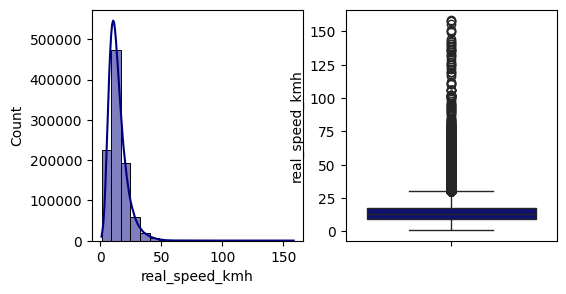

In [13]:
plt.figure(figsize=(6,3))

plt.subplot(1,2,1)
sns.histplot(df_train['real_speed_kmh'], bins=20, kde=True, color='navy')

plt.subplot(1,2,2)
sns.boxplot(data=df_train, y='real_speed_kmh', color='navy')


<Axes: ylabel='duration_minutes'>

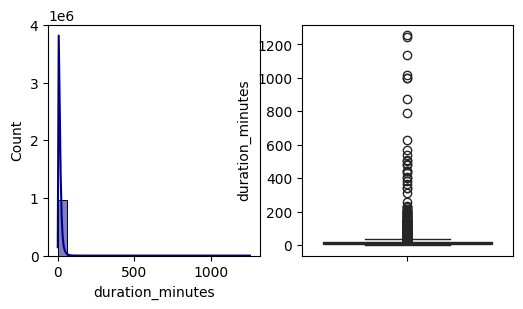

In [14]:
plt.figure(figsize=(6,3))

plt.subplot(1,2,1)
sns.histplot(df_train['duration_minutes'], bins=20, kde=True, color='navy')

plt.subplot(1,2,2)
sns.boxplot(data=df_train, y='duration_minutes', color='navy')

In [15]:
print(df_train['duration_minutes'].max())

1255.85


In [16]:
#that is not correct 1255.85
df_train = df_train[df_train['duration_minutes']<=120]
df_val = df_val[df_val['duration_minutes']<=120]

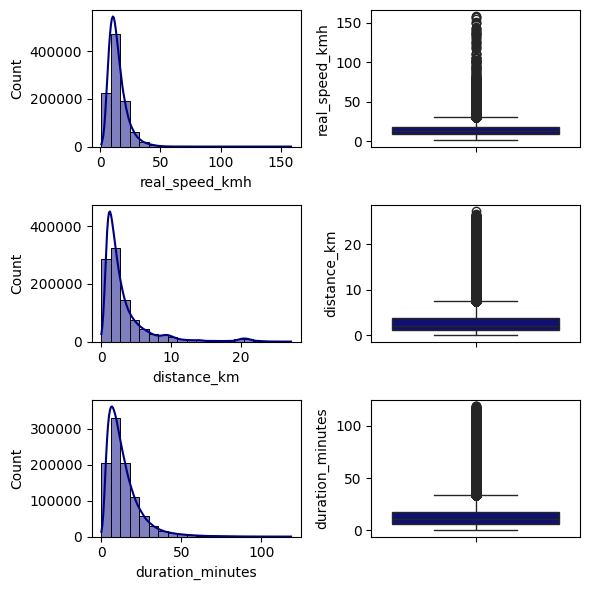

In [17]:


plt.figure(figsize=(6,6))

plt.subplot(3,2,1)
sns.histplot(df_train['real_speed_kmh'], bins=20, kde=True, color='navy')

plt.subplot(3,2,2)
sns.boxplot(data=df_train, y='real_speed_kmh', color='navy')

plt.subplot(3,2,3)
sns.histplot(df_train['distance_km'], bins=20, kde=True, color='navy')

plt.subplot(3,2,4)
sns.boxplot(data=df_train, y='distance_km', color='navy')

plt.subplot(3,2,5)
sns.histplot(df_train['duration_minutes'], bins=20, kde=True, color='navy')

plt.subplot(3,2,6)
sns.boxplot(data=df_train, y='duration_minutes', color='navy')

plt.tight_layout()
plt.show()

<Axes: xlabel='log_trip_duration', ylabel='Density'>

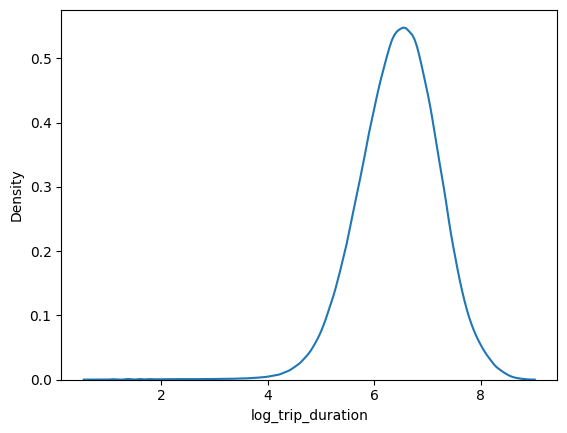

In [18]:
df_train['log_trip_duration'] = np.log1p(df_train['trip_duration'])
df_val['log_trip_duration'] = np.log1p(df_val['trip_duration'])
df_test['log_trip_duration'] = np.log1p(df_test['trip_duration'])
sns.kdeplot(df_train["log_trip_duration"])

<Axes: xlabel='distance_km', ylabel='log_trip_duration'>

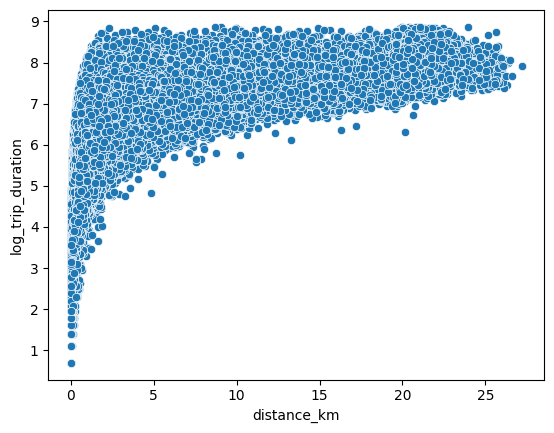

In [19]:
sns.scatterplot(x = 'distance_km', y = 'log_trip_duration', data = df_train)

In [20]:
pt_distance = PowerTransformer(method='yeo-johnson', standardize=True)
df_train['distance_km'] = pt_distance.fit_transform(df_train[['distance_km']])
df_val['distance_km'] = pt_distance.transform(df_val[['distance_km']])
df_test['distance_km'] = pt_distance.transform(df_test[['distance_km']])

<Axes: xlabel='distance_km', ylabel='Count'>

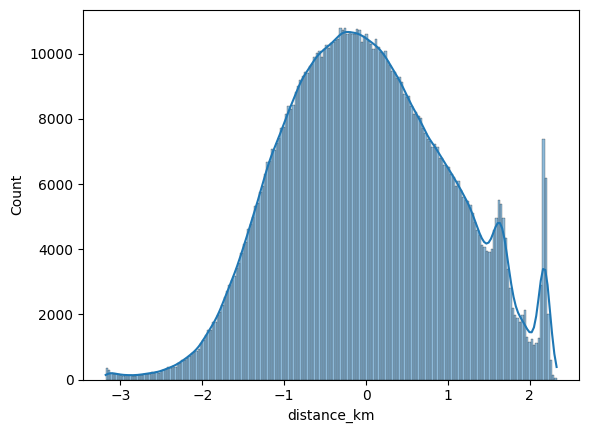

In [21]:
sns.histplot(df_train["distance_km"], kde = True)

<Axes: xlabel='distance_km', ylabel='log_trip_duration'>

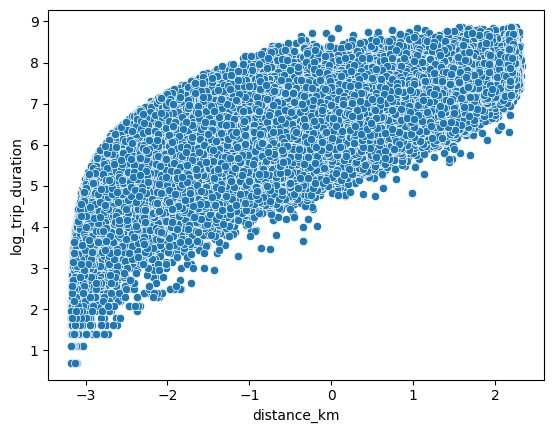

In [22]:
sns.scatterplot(x = 'distance_km', y = 'log_trip_duration', data = df_train)

In [23]:

import holidays

def extract_time_features(df):
    df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
    
    df['pickup_month']   = df['pickup_datetime'].dt.month
    df['pickup_day']     = df['pickup_datetime'].dt.day
    df['pickup_hour']    = df['pickup_datetime'].dt.hour
    df['pickup_weekday'] = df['pickup_datetime'].dt.weekday

    df['hour_sin'] = np.sin(2 * np.pi * df['pickup_hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['pickup_hour'] / 24)
    df['weekday_sin'] = np.sin(2 * np.pi * df['pickup_weekday'] / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * df['pickup_weekday'] / 7)
    
    df['is_weekend'] = (df['pickup_weekday'] >= 5).astype(int)
    
    df['is_rush_hour'] = 0
    mask_weekday = df['pickup_weekday'] < 5
    mask_morning = (df['pickup_hour'] >= 7) & (df['pickup_hour'] < 10)
    mask_evening = (df['pickup_hour'] >= 16) & (df['pickup_hour'] < 19)
    
    df.loc[mask_weekday & (mask_morning | mask_evening), 'is_rush_hour'] = 1
    
    df['is_late_night'] = ((df['pickup_hour'] >= 23) | (df['pickup_hour'] < 5)).astype(int)
    
    us_holidays = holidays.US(state='NY', years=df['pickup_datetime'].dt.year.unique())
    df['is_holiday'] = df['pickup_datetime'].dt.date.apply(lambda x: 1 if x in us_holidays else 0)

    return df

df_train = extract_time_features(df_train)
df_val = extract_time_features(df_val)
df_test = extract_time_features(df_test)

In [24]:
df_train['pickup_month'].unique()

array([6, 4, 5, 3, 2, 1], dtype=int32)

In [25]:
df_train['pickup_day'].unique()

array([ 8,  3,  5, 12, 14, 17, 22, 13,  2, 21, 18, 16,  9, 29, 24,  6, 27,
       25, 20, 30, 28,  4, 26,  1, 31,  7, 15, 11, 23, 19, 10],
      dtype=int32)

/tmp/ipykernel_73769/3948352218.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=group_month_df, x='pickup_month', y='id',  palette = 'mako')


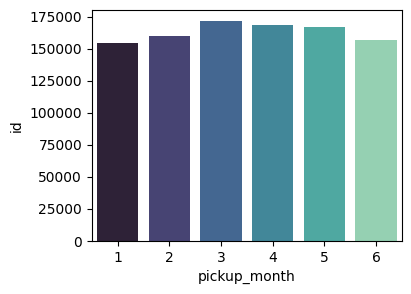

   pickup_month      id
0             1  154112
1             2  160202
2             3  171867
3             4  168129
4             5  166517
5             6  156663


In [26]:
group_month = df_train.groupby('pickup_month')['id'].count()
group_month_df = group_month.reset_index()

plt.figure(figsize=(4,3))
sns.barplot(data=group_month_df, x='pickup_month', y='id',  palette = 'mako')
plt.show()

print(group_month_df)

/tmp/ipykernel_73769/3597643869.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=group_day_df, x='pickup_day', y='id',  palette = 'mako')


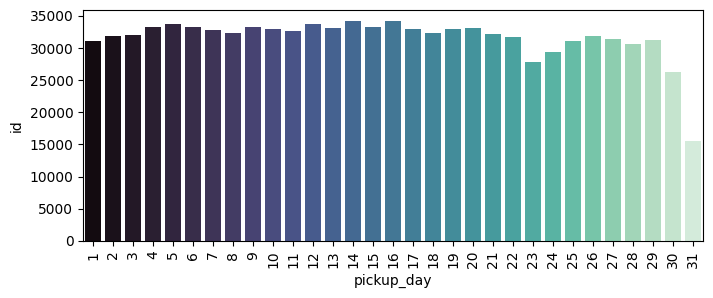

    pickup_day     id
0            1  31107
1            2  31925
2            3  32031
3            4  33220
4            5  33679
5            6  33239
6            7  32818
7            8  32250
8            9  33211
9           10  32878
10          11  32702
11          12  33688
12          13  33135
13          14  34168
14          15  33201
15          16  34220
16          17  32953
17          18  32262
18          19  32950
19          20  33028
20          21  32209
21          22  31655
22          23  27784
23          24  29376
24          25  31035
25          26  31831
26          27  31317
27          28  30584
28          29  31289
29          30  26266
30          31  15479


In [27]:


group_day = df_train.groupby('pickup_day')['id'].count()
group_day_df = group_day.reset_index()

plt.figure(figsize=(8,3))
sns.barplot(data=group_day_df, x='pickup_day', y='id',  palette = 'mako')
plt.xticks(rotation=90)
plt.show()

print(group_day_df)



/tmp/ipykernel_73769/649590776.py:5: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=group_hour_df, x='pickup_hour', y='id',  palette = 'mako', marker='o')


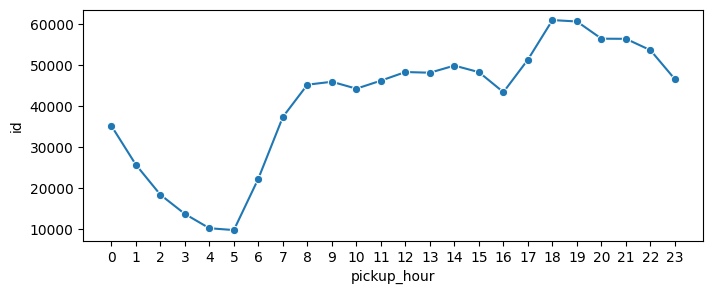

    pickup_hour     id
0             0  35187
1             1  25714
2             2  18409
3             3  13727
4             4  10249
5             5   9796
6             6  22329
7             7  37329
8             8  45180
9             9  45892
10           10  44211
11           11  46164
12           12  48258
13           13  48094
14           14  49827
15           15  48229
16           16  43359
17           17  51291
18           18  60902
19           19  60560
20           20  56374
21           21  56343
22           22  53569
23           23  46497


In [28]:
group_hour = df_train.groupby('pickup_hour')['id'].count()
group_hour_df = group_hour.reset_index()

plt.figure(figsize=(8,3))
sns.lineplot(data=group_hour_df, x='pickup_hour', y='id',  palette = 'mako', marker='o')
plt.xticks(group_hour_df.index)
plt.show()

print(group_hour_df)

In [29]:
def selection_columns(df):
    numerical_cols = [
        'pickup_longitude','pickup_latitude',
        'dropoff_longitude','dropoff_latitude',
        'distance_km',
        'hour_sin','hour_cos',
        'weekday_sin','weekday_cos',
        'pickup_day','pickup_month'
    ]

    binary_cols = ['is_weekend','is_rush_hour','is_late_night','is_holiday']

    categorical_cols_to_encode = ['vendor_id']

    df_encoded = pd.get_dummies(df, columns=categorical_cols_to_encode, drop_first=True)

    final_features = numerical_cols + binary_cols + [c for c in df_encoded.columns if 'vendor_id' in c]

    return df_encoded, final_features

df_train_encoded, final_features = selection_columns(df_train)

X_train = df_train_encoded[final_features]
y_train = df_train_encoded['log_trip_duration']

df_val_encoded = pd.get_dummies(df_val, columns=['vendor_id'], drop_first=True)
df_val_encoded = df_val_encoded.reindex(columns=df_train_encoded.columns, fill_value=0)

X_val = df_val_encoded[final_features]
y_val = df_val_encoded['log_trip_duration']

df_test_encoded = pd.get_dummies(df_test, columns=['vendor_id'], drop_first=True)
df_test_encoded = df_test_encoded.reindex(columns=df_train_encoded.columns, fill_value=0)

X_test = df_test_encoded[final_features]
y_test = df_test_encoded['log_trip_duration']

In [31]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import numpy as np


class Trainer:

    def __init__(self):
        self.scaler = MinMaxScaler()

    def train(self, model, X_train, y_train):
        X_scaled = self.scaler.fit_transform(X_train)
        model.fit(X_scaled, y_train)
        return model

    def val(self, model, X_val, y_val):
        X_scaled = self.scaler.transform(X_val)

        pred = model.predict(X_scaled)

        print("R2 =", r2_score(y_val, pred))
        print("RMSE =", np.sqrt(mean_squared_error(y_val, pred)))


trainer = Trainer()

ridge = Ridge(alpha=1)
xgb = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=5)
nn = MLPRegressor(hidden_layer_sizes=(64,32), max_iter=1000)

ridge = trainer.train(ridge, X_train, y_train)
trainer.val(ridge, X_val, y_val)

xgb = trainer.train(xgb, X_train, y_train)
trainer.val(xgb, X_val, y_val)

nn = trainer.train(nn, X_train, y_train)
trainer.val(nn, X_val, y_val)

R2 = 0.7021690614102777
RMSE = 0.40929051678437306
R2 = 0.7781131185381741
RMSE = 0.35327474396680514
R2 = 0.8091668402331491
RMSE = 0.327622483253543


In [32]:
ridge_weights = pd.Series(ridge.coef_, index=final_features)
print("=== Ridge Weights ===")
print(ridge_weights)

print("\nRidge Bias:", ridge.intercept_)

=== Ridge Weights ===
pickup_longitude    -0.157371
pickup_latitude     -0.160488
dropoff_longitude   -0.288682
dropoff_latitude    -0.299657
distance_km          3.452020
hour_sin            -0.248976
hour_cos            -0.407818
weekday_sin          0.065901
weekday_cos         -0.106355
pickup_day           0.011790
pickup_month         0.070417
is_weekend          -0.049927
is_rush_hour         0.083090
is_late_night        0.072022
is_holiday          -0.111775
vendor_id_2          0.002842
dtype: float64

Ridge Bias: 5.058874682258636


In [ ]:
ridge = trainer.train(ridge, X_train, y_train)
trainer.val(ridge, X_test, y_test)

xgb = trainer.train(xgb, X_train, y_train)
trainer.val(xgb, X_test, y_test)

nn = trainer.train(nn, X_train, y_train)
trainer.val(nn, X_test, y_test)

R2 = 0.6341895309817831
RMSE = 0.47683374273902795
R2 = 0.6858236467216332
RMSE = 0.4419016899148919
